<img src="images/strathsdr_banner.png" align="left" >

# RFSoC OFDM Transceiver
----

<div class="alert alert-box alert-info">
Please use Jupyter Labs http://board_ip_address/lab for this notebook.
</div>

This notebook demonstrates the implementation of an Orthogonal Frequency Division Multiplexing (OFDM) transceiver on RFSoC. PYNQ is used to control the underlying modulation scheme of the OFDM sub-carriers and for visualisation of data at various stages in the transmit/receive chain, such as the received constellations.       

## Aims 
* To demonstrate a complete OFDM transceiver.
* Explain the various stages OFDM comprises.
* Provide an interactive and responsive means to inspect the data at each stage.

## Table of Contents
* [Introduction](#introduction)
    * [Hardware Setup](#hardware-setup)
    * [Software Setup](#software-setup)
* [Transmit](#transmit)
    * [Symbol Generation](#symbol-gen)
* [Receive](#creating-images)
    * [Constellation Plot](#constellation-plot)
* [Conclusion](#conclusion)

## References
* [Xilinx, Inc, "USP RF Data Converter: LogiCORE IP Product Guide", PG269, v2.4, November 2020](https://www.xilinx.com/support/documentation/ip_documentation/usp_rf_data_converter/v2_4/pg269-rf-data-converter.pdf)

## Revision History
* **v1.0** | 26/02/2021 | OFDM transceiver notebook
* **v1.1** | 30/03/2022 | OFDM DUC and DDC change
* **v1.2** | 17/05/2023 | General notebook for all boards.

----

## Introduction <a class="anchor" id="introduction"></a>

The demonstrator is a complete OFDM transceiver. This notebook will explain each stage of the system with a combination of text, diagrams and live data capture. [Figure 1](#fig-1) below provides an overview of the system.

<a class="anchor" id="fig-1"></a>
<figure>
<img src="./images/system_overview.png" height='75%' width='75%'/>
    <figcaption><b>Figure 1: OFDM Demonstrator System Overview</b></figcaption>
</figure>

The OFDM system starts with generation of random data symbols from 1 of 10 possible modulation schemes (BPSK to 1024 QAM), based on input provided from PYNQ. In accordance with the procedure used in the IEEE 802.11a/g standard, the symbols are grouped into blocks of 48 for mapping to sub-carriers. The OFDM symbol consists of 48 data sub-carriers, 4 pilot sub-carriers and 12 null sub-carriers (including DC). The final OFDM symbol is created by performing a 64 point IFFT and adding a 16 sample Cyclic Prefix (CP). The transmitted signal consists of a continuous stream of OFDM symbols. At the very beginning of the data stream, the L-STF and L-LTF training symbols from the IEEE 802.11a/g standard are transmitted, to aid synchronisation and channel estimation tasks in the receiver. 

In the receiver, timing and frequency synchronisation are performed to acquire symbol timing and correct for any frequency offsets. Once timing is achieved, the FFT is performed to recover the underlying data symbols in each OFDM symbol. The L-LTF symbols are used to estimate the channel frequency response at each sub-carrier position, which subsequently allows the data to be equalised. Finally, the pilot symbols are used to correct for residual phase errors in the phase tracking stage. The recovered symbols are then passed into the PS for visualisation in PYNQ.

### Hardware Setup <a class="anchor" id="hardware-setup"></a>
Your RFSoC development board should be setup in single channel mode with a loopback cable connected between an ADC and DAC.

See the setup instructions [here](01_rfsoc_ofdm_setup.ipynb) for more information.

<div class="alert alert-box alert-danger">
<b>Caution:</b>
    In this demonstration, we generate tones using the RFSoC development board. Your device should be setup in loopback mode. You should understand that the RFSoC platform can also transmit RF signals wirelessly. Remember that unlicensed wireless transmission of RF signals may be illegal in your geographical location. Radio signals may also interfere with nearby devices, such as pacemakers and emergency radio equipment. Note that it is also illegal to intercept and decode particular RF signals. If you are unsure, please seek professional support.
</div>

### Software Setup
The setup for the OFDM demonstration system is nearly complete. The majority of the libraries used by the demonstrator design are contained inside the RFSoC-OFDM software package. We only need to run a few code cells to initialise the environment.

In [1]:
from rfsoc_ofdm.overlay import Overlay
import ipywidgets as ipw

ofdm_hw = Overlay()

display(ofdm_hw.ofdm_transmitter.modulation_dropdown.get_widget())

display(ipw.VBox([
    ofdm_hw.inspectors['constellation'].constellation_plot(),
    ofdm_hw.inspectors['constellation'].plot_control()
]))----

## Transmit <a class="anchor" id="transmit"></a>

### Symbol Generation <a class="anchor" id="symbol-gen"></a>
There are a total of 10 modulation schemes available to be transmitted. These are generated on the programmable logic and can be chosen between by updating the *ofdm_tx IP core's* **mod** register with a value from 0-9 over AXI4-Lite. [Figure 2](#fig-2) illustrates the IP core as a simplified block diagram.

<a class="anchor" id="fig-2"></a>
<figure>
<img src="./images/symbol_generation.png" height='45%' width='45%'/>
    <figcaption><b>Figure 2: Symbol generation block diagram.</b></figcaption>
</figure>


This drop down widget sends the value associated with each modulation scheme to the ofdm_tx core. Run the cell to use it.

In [2]:
ofdm_hw.ofdm_transmitter.modulation_dropdown.get_widget()

Dropdown(description='Modulation Scheme: ', layout=Layout(width='300px'), options=('BPSK', 'QPSK', '8-PSK', '1…

The output of the symbol generation block has been tapped off, allowing for the live symbols to be visualised in Jupyter Lab. Run the cell below and hit play on the chart to inspect the symbols generated on the programmable logic.

In [3]:
ipw.VBox([ofdm_hw.inspectors['transmitter'].time_plot(),
          ofdm_hw.inspectors['transmitter'].plot_control()])

    'data': [{'name': 'Real Signal',
              'type': 'scatter',
          …

---

## Receive

### Constellation Plot <a class="anchor" id="constellation-plot"></a>

Run the cell below to see the output of the OFDM receiver displayed as a constellation: 

In [4]:
ipw.VBox([ofdm_hw.inspectors['constellation'].constellation_plot(),
          ofdm_hw.inspectors['constellation'].plot_control()])

    'data': [{'mode': 'markers',
              'type': 'scatter',
              …

In [7]:
from pathlib import Path
from datetime import datetime
import numpy as np
import json

mod = ofdm_hw.ofdm_transmitter.modulation
out = Path.home() / "jupyter_notebooks" / "ofdm_captures"
out = out / (datetime.now().strftime("%Y%m%d_%H%M%S_%f") + "_" + mod)
out.mkdir(parents=True, exist_ok=False)

iq = ofdm_hw.inspectors["constellation"].get_frame()
np.save(out / "iq.npy", iq)

meta = {
    "modulation": mod,
    "capture_point": "receiver constellation",
    "samples": int(iq.size),
    "tx_gain": float(ofdm_hw.ofdm_transmitter.gain)
}
(out / "meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")

print("保存位置：", out)
print("调制：", mod)
print("样本数量：", iq.size)

保存位置： /root/jupyter_notebooks/ofdm_captures/20250730_120834_805327_16-QAM
调制： 16-QAM
样本数量： 1024


样本数量： 1024
保存前后完全一致： True


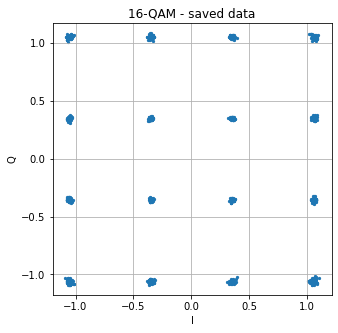

In [8]:
import matplotlib.pyplot as plt

saved_iq = np.load(out / "iq.npy")

print("样本数量：", saved_iq.size)
print("保存前后完全一致：", np.array_equal(iq, saved_iq))

plt.figure(figsize=(5, 5))
plt.scatter(saved_iq.real, saved_iq.imag, s=5)
plt.axis("equal")
plt.xlabel("I")
plt.ylabel("Q")
plt.title(mod + " - saved data")
plt.grid(True)
plt.savefig(out / "constellation.png", dpi=150)
plt.show()

Try changing the modulation scheme using the code cell that was ran earlier. You should be able to visualise the modulation schemes in the plot above.

## Conclusion <a class="anchor" id="conclusion"></a>
This notebook has demonstrated a live OFDM transceiver operating on an RFSoC. It has been shown how PYNQ can be used to interact with various parts of the hardware design, offering control of the system and visualisation of data. 

* The various components comprising the OFDM transmitter and receiver have been introduced at a high level. 
    * Modulation symbols were inspected.
    * The received and sychronised constellation were plotted.
* Interacted with a real-time RF system.
    * Changed modulation scheme.

----

⬅️ [Previous Notebook](01_rfsoc_ofdm_setup.ipynb) | [Next Notebook](03_voila_rfsoc_ofdm_demonstrator.ipynb) 🚀

----
----